# Task 1.3 - Feature Detection and Matching

**Module:** FCVG101 Introduction to Computer Vision

## Objective
* Detect interest points: **Harris corners** (written from scratch and compared with OpenCV), **SIFT** and **ORB** keypoints.
* Match the keypoints of an object image (`box.png`) with a cluttered scene (`box_in_scene.png`) using **k-NN matching + Lowe's ratio test**.
* Remove remaining wrong matches with a **RANSAC homography** and draw the outline of the box in the scene.
* Compare SIFT and ORB (number of matches, inliers, speed).

## Theory (short)

**Harris corner.** A corner is a point where the image changes in *every* direction. With image derivatives `Ix, Iy` we build, for each pixel, the structure tensor summed over a small window `w`:

$$ M = \sum_w \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix}, \qquad R = \det(M) - k\,\operatorname{trace}(M)^2 $$

`R` large and positive = corner (both eigenvalues of M large), `R` negative = edge (one large eigenvalue), `R` near 0 = flat region. We keep local maxima of `R` above a threshold (non-maximum suppression).

**SIFT** finds blobs in a scale space (difference of Gaussians), so it is scale and rotation invariant, and describes each keypoint with a 128-dimensional gradient-histogram vector (compared with the L2 distance). **ORB** uses FAST corners + a rotated BRIEF *binary* descriptor of 256 bits (compared with the Hamming distance); it is much faster but less distinctive.

**Lowe's ratio test.** For a descriptor we find its two nearest neighbours in the other image, at distances `d1 <= d2`. A correct match should be much closer than the second-best candidate, so we keep the match only if `d1 < 0.75 * d2`. Ambiguous descriptors (repeated texture) are rejected.

**RANSAC homography.** The box is (almost) planar, so its points in the two images are related by a 3 x 3 homography `H`. RANSAC repeatedly fits `H` to 4 random matches and keeps the model supported by the most matches (inliers: reprojection error < 5 px). Matches that do not fit are outliers.

In [1]:
# --- Setup: find the project root (the folder that contains "src") and import our modules ---
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent          # walk up until we find the folder that has "src"
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.task1.results import update_results

TASK1 = ROOT / "Task1"
OUT = TASK1 / "outputs"
OUT.mkdir(exist_ok=True)
RESULTS_JSON = OUT / "task1_results.json"   # all key numbers are collected here

def show(ax, img, title="", cmap=None):
    """Show an OpenCV image (BGR or gray) on a matplotlib axis."""
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # matplotlib expects RGB
        ax.imshow(img)
    else:
        ax.imshow(img, cmap=cmap or "gray", vmin=0 if img.dtype == np.uint8 else None,
                  vmax=255 if img.dtype == np.uint8 else None)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

print("Project root:", ROOT.name)

from src.task1.features import (
    harris_from_scratch, harris_opencv, detect_keypoints, match_features, match_best_only,
    find_homography_ransac, draw_object_outline, draw_matches, match_images,
)

cv2.setRNGSeed(0)   # RANSAC is random; fix the seed so the numbers are reproducible
box = cv2.imread(str(TASK1 / "featureMatch_data" / "box.png"))
scene = cv2.imread(str(TASK1 / "featureMatch_data" / "box_in_scene.png"))
print("box:", box.shape, " scene:", scene.shape)

Project root: FCVG101_Coursework
box: (223, 324, 3)  scene: (384, 512, 3)


## Step 1 - Harris corners: from scratch vs OpenCV
`harris_from_scratch` follows the formula above (Sobel -> Ixx, Iyy, Ixy smoothed with a 3x3 Gaussian -> `R = det - k trace^2` -> threshold 1 % of max -> 3x3 non-maximum suppression). `harris_opencv` uses `cv2.cornerHarris` (block size 3, Sobel 3, k = 0.04) followed by the same thresholding and suppression, so the comparison is fair. Red = from scratch, green = OpenCV.

Corners: from scratch = 536, cv2.cornerHarris = 620
98% of our corners have an OpenCV corner within 3 px; 95% of OpenCV's have one of ours
Correlation between the two response maps: 0.9510


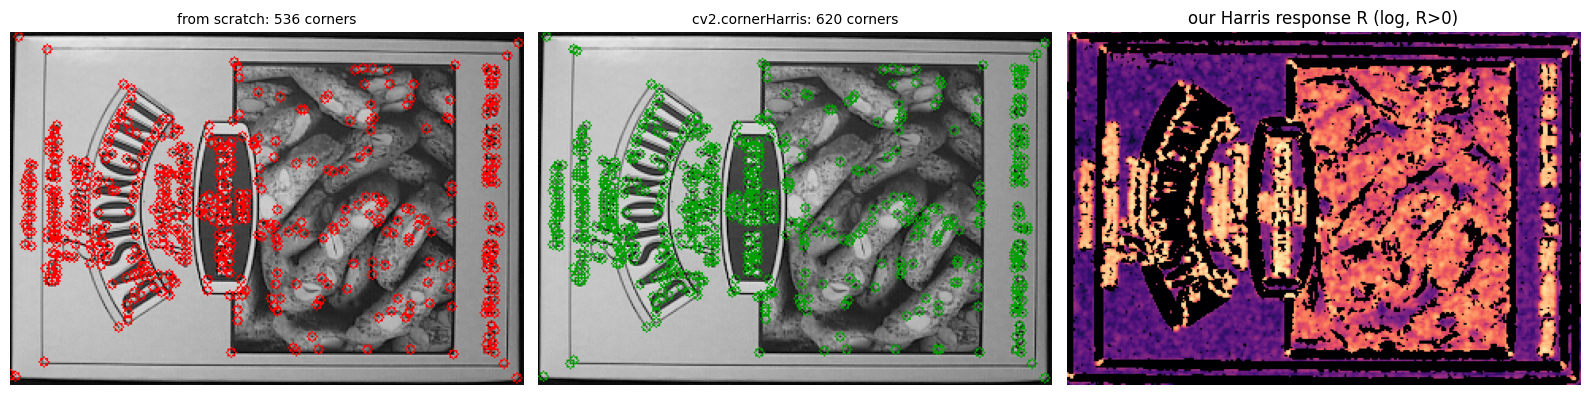

In [2]:
gray_box = cv2.cvtColor(box, cv2.COLOR_BGR2GRAY)
mine = harris_from_scratch(gray_box, k=0.04, window=3, thresh_ratio=0.01)
ref = harris_opencv(gray_box, k=0.04, block_size=3, thresh_ratio=0.01)

def overlay(img, corners, color):
    out = img.copy()
    for x, y in corners:
        cv2.circle(out, (int(x), int(y)), 3, color, 1)
    return out

# how many corners of ours have an OpenCV corner within 3 px (and vice versa)?
d = np.linalg.norm(mine["corners"][:, None, :] - ref["corners"][None, :, :], axis=2)
match_ours = float((d.min(axis=1) <= 3).mean())
match_ref = float((d.min(axis=0) <= 3).mean())
resp_corr = float(np.corrcoef(mine["response"].ravel(), ref["response"].ravel())[0, 1])
print(f"Corners: from scratch = {len(mine['corners'])}, cv2.cornerHarris = {len(ref['corners'])}")
print(f"{match_ours:.0%} of our corners have an OpenCV corner within 3 px; {match_ref:.0%} of OpenCV's have one of ours")
print(f"Correlation between the two response maps: {resp_corr:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
show(axes[0], overlay(box, mine["corners"], (0, 0, 255)), f"from scratch: {len(mine['corners'])} corners")
show(axes[1], overlay(box, ref["corners"], (0, 160, 0)), f"cv2.cornerHarris: {len(ref['corners'])} corners")
axes[2].imshow(np.log1p(np.maximum(mine["response"], 0)), cmap="magma"); axes[2].set_title("our Harris response R (log, R>0)"); axes[2].axis("off")
plt.tight_layout()
plt.savefig(OUT / "harris_compare.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 2 - SIFT and ORB keypoints
`detect_keypoints(img, method)` returns the keypoints and their descriptors. The circle size shows the scale of each keypoint (SIFT) and the line shows its orientation.

SIFT  keypoints: box = 604, scene = 969;  descriptor shape (604, 128), dtype float32
ORB   keypoints: box = 1252, scene = 1500;  descriptor shape (1252, 32), dtype uint8


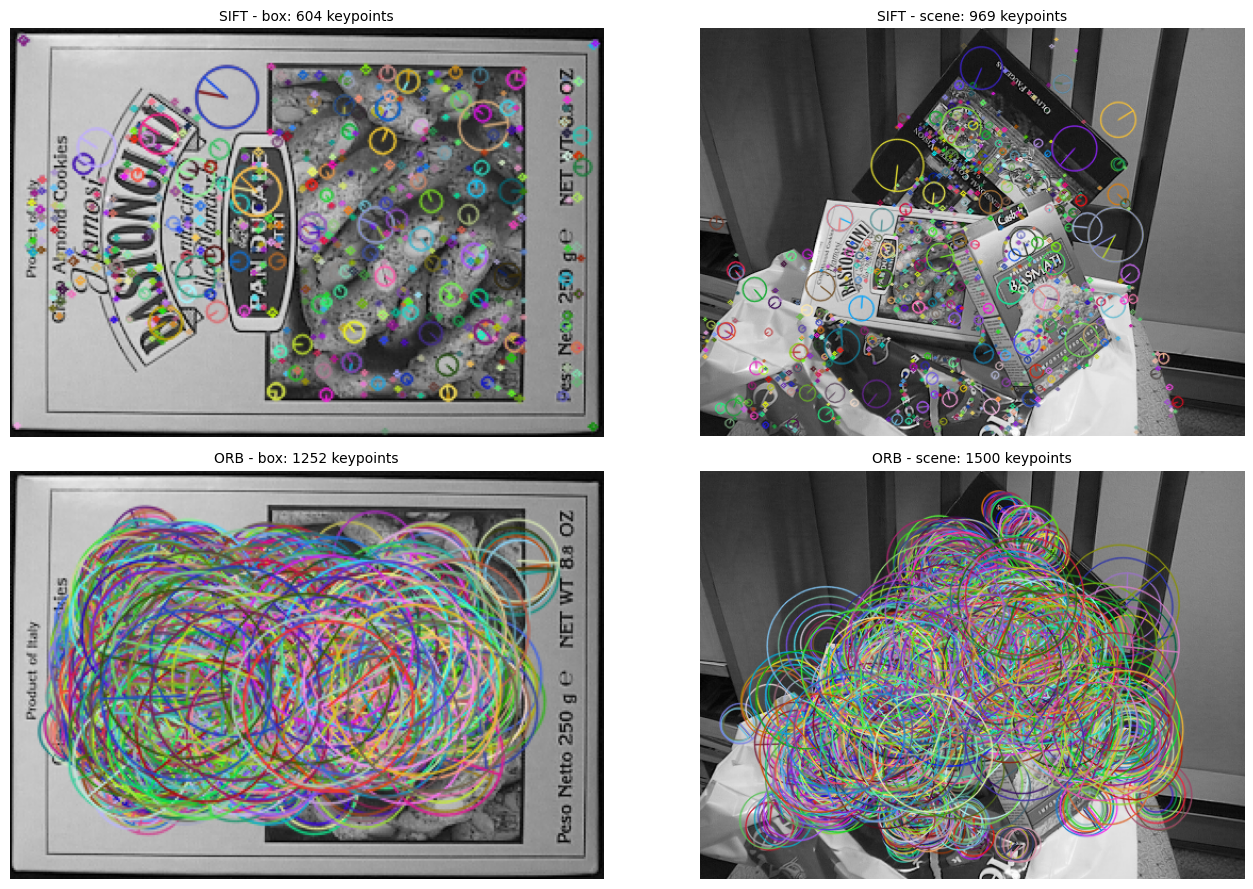

In [3]:
kp = {}
for method in ["sift", "orb"]:
    kp[method] = {"box": detect_keypoints(box, method), "scene": detect_keypoints(scene, method)}
    kpb, desb = kp[method]["box"]; kps, dess = kp[method]["scene"]
    print(f"{method.upper():5s} keypoints: box = {len(kpb)}, scene = {len(kps)};  descriptor shape {desb.shape}, dtype {desb.dtype}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for r, method in enumerate(["sift", "orb"]):
    for c, (name, img) in enumerate([("box", box), ("scene", scene)]):
        keypoints = kp[method][name][0]
        vis = cv2.drawKeypoints(img, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        show(axes[r, c], vis, f"{method.upper()} - {name}: {len(keypoints)} keypoints")
plt.tight_layout()
plt.savefig(OUT / "keypoints_sift_orb.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 3 - Matching WITHOUT the ratio test (baseline)
Baseline: every descriptor of the box takes its single nearest neighbour in the scene, with cross-check (the scene descriptor must also pick this box descriptor as its nearest). Nothing checks whether the match is *distinctive*. We then run RANSAC to count how many of these matches are actually geometrically consistent. Green lines = RANSAC inliers (correct), red = outliers (wrong).

SIFT  no ratio test (cross-check): 260 matches, 88 RANSAC inliers, inlier ratio 33.8%
ORB   no ratio test (cross-check): 396 matches, 53 RANSAC inliers, inlier ratio 13.4%


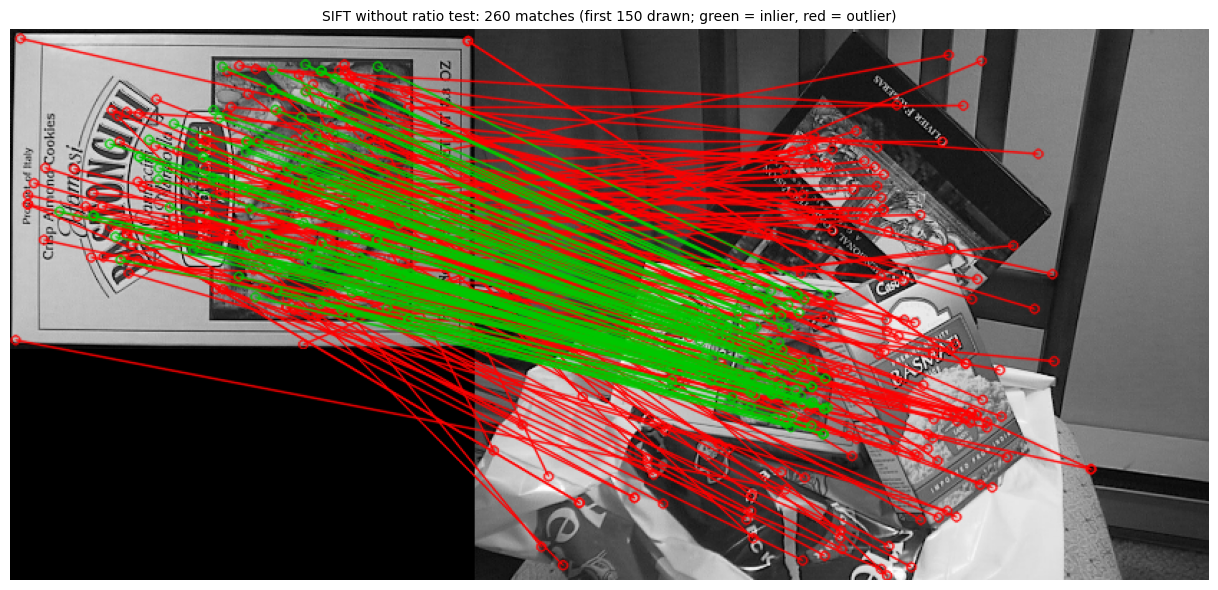

In [4]:
def evaluate(method, matches):
    kp1, kp2 = kp[method]["box"][0], kp[method]["scene"][0]
    H, mask = find_homography_ransac(kp1, kp2, matches)
    n_in = int(sum(mask))
    return H, mask, n_in

baseline = {}
for method in ["sift", "orb"]:
    des1, des2 = kp[method]["box"][1], kp[method]["scene"][1]
    m = match_best_only(des1, des2, method)
    H, mask, n_in = evaluate(method, m)
    baseline[method] = {"matches": len(m), "inliers": n_in}
    print(f"{method.upper():5s} no ratio test (cross-check): {len(m)} matches, {n_in} RANSAC inliers, inlier ratio {n_in/len(m):.1%}")

m = match_best_only(kp["sift"]["box"][1], kp["sift"]["scene"][1], "sift")
H, mask, _ = evaluate("sift", m)
vis_noratio = draw_matches(box, kp["sift"]["box"][0], scene, kp["sift"]["scene"][0], m, mask, max_draw=150)
plt.figure(figsize=(14, 6)); show(plt.gca(), vis_noratio, f"SIFT without ratio test: {len(m)} matches (first 150 drawn; green = inlier, red = outlier)")
plt.tight_layout()
plt.savefig(OUT / "matches_sift_noratio.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 4 - Matching WITH the ratio test (0.75) + RANSAC
`match_images(box, scene, method, ratio)` runs the whole pipeline: detect -> BFMatcher k-NN (k = 2) -> ratio test -> RANSAC homography -> draw matches and the box outline. It returns the picture plus all counts and the time.

SIFT  keypoints 604/969 | nearest-neighbour matches 604 | after ratio test 80 | RANSAC inliers 75 (93.8%) | 31 ms
ORB   keypoints 1252/1500 | nearest-neighbour matches 1252 | after ratio test 46 | RANSAC inliers 43 (93.5%) | 10 ms


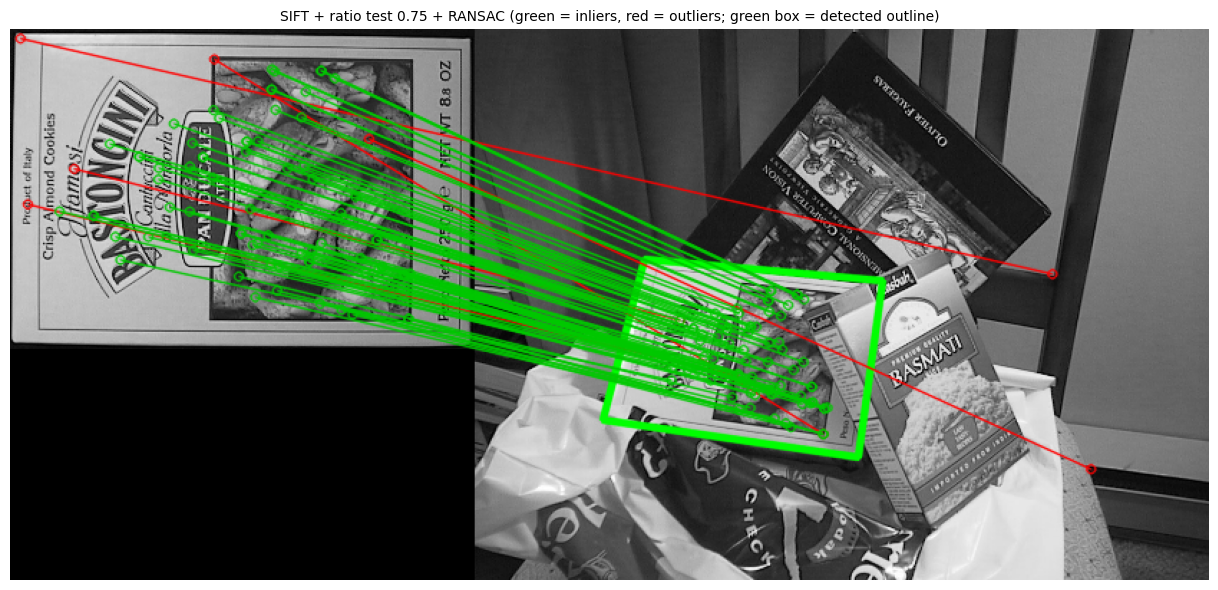

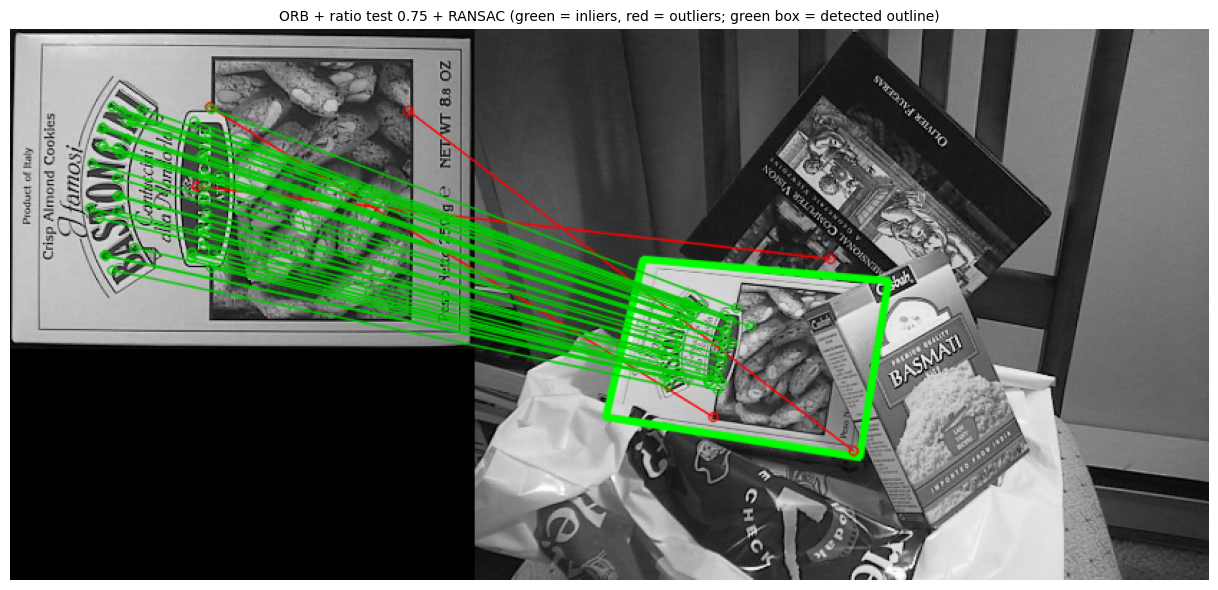

In [5]:
res = {}
for method in ["sift", "orb"]:
    res[method] = match_images(box, scene, method, ratio=0.75)
    r = res[method]
    print(f"{method.upper():5s} keypoints {r['n_keypoints1']}/{r['n_keypoints2']} | nearest-neighbour matches {r['n_raw_matches']} | "
          f"after ratio test {r['n_good_matches']} | RANSAC inliers {r['n_inliers']} ({r['inlier_ratio']:.1%}) | {r['time_s']*1000:.0f} ms")

for method, fname in [("sift", "matches_sift_ratio.png"), ("orb", "matches_orb_ratio.png")]:
    plt.figure(figsize=(14, 6))
    show(plt.gca(), res[method]["visualization"], f"{method.upper()} + ratio test 0.75 + RANSAC (green = inliers, red = outliers; green box = detected outline)")
    plt.tight_layout()
    plt.savefig(OUT / fname, dpi=120, bbox_inches="tight")
    plt.show()

## Step 5 - Effect of the ratio threshold
A small ratio keeps only very distinctive matches (few, but almost all correct); a large ratio keeps almost everything (more matches, but more wrong ones). We sweep the threshold from 0.5 to 0.95 and count the matches that survive the ratio test and those that survive RANSAC.

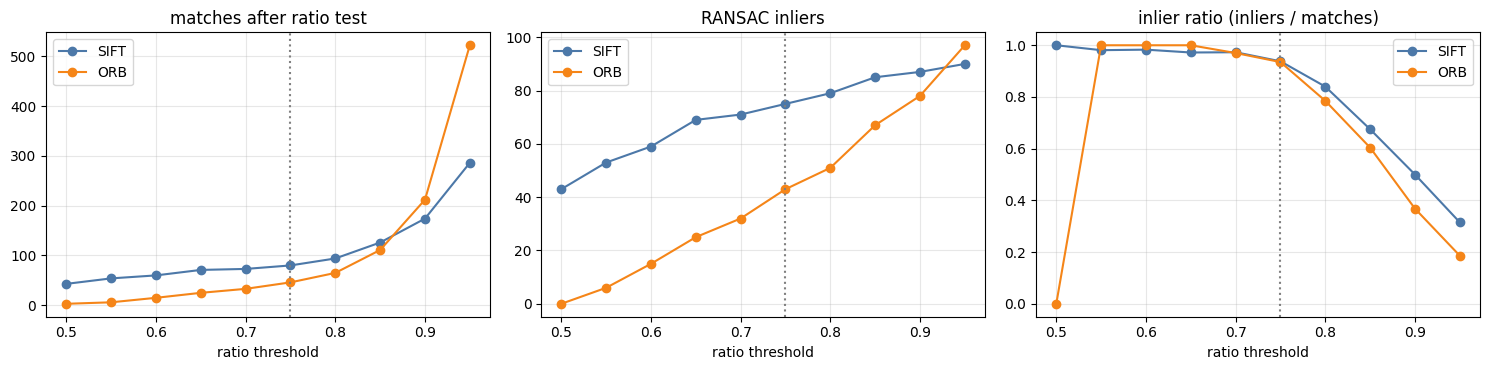

good_matches        inliers       inlier_ratio       
method          ORB   SIFT     ORB  SIFT          ORB   SIFT
ratio                                                       
0.50            3.0   43.0     0.0  43.0        0.000  1.000
0.55            6.0   54.0     6.0  53.0        1.000  0.981
0.60           15.0   60.0    15.0  59.0        1.000  0.983
0.65           25.0   71.0    25.0  69.0        1.000  0.972
0.70           33.0   73.0    32.0  71.0        0.970  0.973
0.75           46.0   80.0    43.0  75.0        0.935  0.938
0.80           65.0   94.0    51.0  79.0        0.785  0.840
0.85          111.0  126.0    67.0  85.0        0.604  0.675
0.90          212.0  174.0    78.0  87.0        0.368  0.500
0.95          522.0  286.0    97.0  90.0        0.186  0.315

In [6]:
ratios = np.round(np.arange(0.5, 0.96, 0.05), 2)
sweep_rows = []
for method in ["sift", "orb"]:
    kp1, des1 = kp[method]["box"]; kp2, des2 = kp[method]["scene"]
    for ratio in ratios:
        good = match_features(des1, des2, method, ratio)
        _, mask = find_homography_ransac(kp1, kp2, good)
        sweep_rows.append({"method": method.upper(), "ratio": ratio, "good_matches": len(good), "inliers": int(sum(mask))})
sweep = pd.DataFrame(sweep_rows)
sweep["inlier_ratio"] = (sweep["inliers"] / sweep["good_matches"].replace(0, np.nan)).round(3)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for method, color in [("SIFT", "#4C78A8"), ("ORB", "#F58518")]:
    s = sweep[sweep.method == method]
    axes[0].plot(s.ratio, s.good_matches, "o-", color=color, label=method)
    axes[1].plot(s.ratio, s.inliers, "o-", color=color, label=method)
    axes[2].plot(s.ratio, s.inlier_ratio, "o-", color=color, label=method)
for ax, title in zip(axes, ["matches after ratio test", "RANSAC inliers", "inlier ratio (inliers / matches)"]):
    ax.set_title(title); ax.set_xlabel("ratio threshold"); ax.axvline(0.75, color="gray", ls=":"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "ratio_sweep.png", dpi=120, bbox_inches="tight")
plt.show()
display(sweep.pivot(index="ratio", columns="method", values=["good_matches", "inliers", "inlier_ratio"]))

## Step 6 - Locating the box in the scene
The homography `H` maps the 4 corners of `box.png` into the scene; `draw_object_outline` draws the resulting quadrilateral. If the outline sits on the box in the scene, the matches are geometrically consistent. Note that the box is partly hidden by another object in the scene, and is seen at a different scale and rotation.

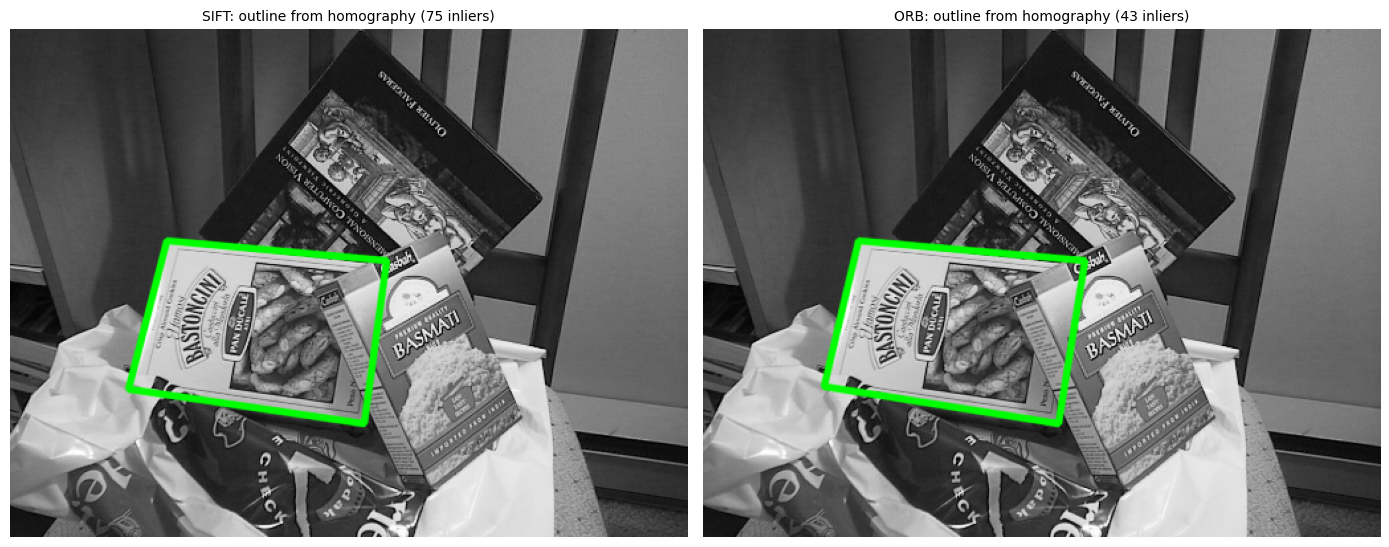

Estimated box corners in the scene (SIFT):
 [[118.8 160.9]
 [284.7 175.1]
 [268.  298.6]
 [ 89.5 272.6]]


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, method in zip(axes, ["sift", "orb"]):
    r = res[method]
    show(ax, r["scene_with_box"], f"{method.upper()}: outline from homography ({r['n_inliers']} inliers)")
plt.tight_layout()
plt.savefig(OUT / "box_localization.png", dpi=120, bbox_inches="tight")
plt.show()

H_sift = np.array(res["sift"]["homography"])
corners = np.float32([[0, 0], [box.shape[1], 0], [box.shape[1], box.shape[0]], [0, box.shape[0]]]).reshape(-1, 1, 2)
print("Estimated box corners in the scene (SIFT):\n", np.round(cv2.perspectiveTransform(corners, H_sift).reshape(-1, 2), 1))

## Step 7 - SIFT vs ORB comparison
Time = detection + description + matching + RANSAC for both images, median of 10 runs.

In [8]:
rows = []
for method in ["sift", "orb"]:
    times = [match_images(box, scene, method, 0.75)["time_s"] for _ in range(10)]
    r = res[method]
    rows.append({"method": method.upper(), "matching": "ratio test 0.75", "keypoints box": r["n_keypoints1"], "keypoints scene": r["n_keypoints2"],
                 "matches": r["n_good_matches"], "RANSAC inliers": r["n_inliers"], "inlier ratio": round(r["inlier_ratio"], 3),
                 "time (ms)": round(float(np.median(times)) * 1000, 1)})
    b = baseline[method]
    rows.append({"method": method.upper(), "matching": "no ratio (cross-check)", "keypoints box": r["n_keypoints1"], "keypoints scene": r["n_keypoints2"],
                 "matches": b["matches"], "RANSAC inliers": b["inliers"], "inlier ratio": round(b["inliers"] / b["matches"], 3), "time (ms)": np.nan})
feature_table = pd.DataFrame(rows)
feature_table.to_csv(OUT / "feature_metrics.csv", index=False)
display(feature_table)

,method,matching,keypoints box,keypoints scene,matches,RANSAC inliers,inlier ratio,time (ms)
0,SIFT,ratio test 0.75,604,969,80,75,0.938,31.5
1,SIFT,no ratio (cross-check),604,969,260,88,0.338,NaN
2,ORB,ratio test 0.75,1252,1500,46,43,0.935,9.7
3,ORB,no ratio (cross-check),1252,1500,396,53,0.134,NaN


In [9]:
# Save all key numbers of notebook 03 for the report
update_results(RESULTS_JSON, "task1_3_features", {
    "description": "Feature detection and matching between box.png (object) and box_in_scene.png (scene).",
    "harris": {"corners_from_scratch": len(mine["corners"]), "corners_opencv": len(ref["corners"]),
               "fraction_ours_within_3px_of_opencv": match_ours, "fraction_opencv_within_3px_of_ours": match_ref,
               "response_map_correlation": resp_corr, "params": "k=0.04, window=3, threshold=1% of max, 3x3 NMS"},
    "ratio_threshold": 0.75,
    "sift_orb_table": feature_table.to_dict(orient="records"),
    "box_corners_in_scene_sift": cv2.perspectiveTransform(corners, H_sift).reshape(-1, 2),
    "homography_sift": res["sift"]["homography"],
    "homography_orb": res["orb"]["homography"],
    "ratio_sweep": sweep.to_dict(orient="records"),
})
print("results saved")

results saved


## Summary / Observations

* **Harris:** our from-scratch detector finds **536 corners** and `cv2.cornerHarris` finds **620** with the same threshold (1 % of the maximum) and the same 3x3 non-maximum suppression. 98 % of our corners have an OpenCV corner within 3 px (95 % the other way round) and the two response maps have a correlation of 0.951. The counts differ a little because OpenCV sums the derivatives over a 3x3 *box* window whereas we smooth with a 3x3 *Gaussian*, which changes the response values near the threshold. Corners concentrate on the lettering and the cookie texture, plus the box corners; Harris is not scale invariant, so it is only used here for comparison.
* **Keypoints:** SIFT finds 604 (box) / 969 (scene) keypoints with 128-D float descriptors; ORB (limited to 1500 features) finds 1252 / 1500 with 32-byte (256-bit) binary descriptors.
* **Without the ratio test** (nearest neighbour + cross-check): SIFT keeps 260 matches of which only 88 are RANSAC inliers (**33.8 %**); ORB keeps 396 matches with only 53 inliers (**13.4 %**). Most of these matches are wrong - the red lines in `matches_sift_noratio.png`.
* **With the ratio test (0.75)** SIFT keeps 80 matches, **75 inliers (93.8 %)**; ORB keeps 46 matches, **43 inliers (93.5 %)**. The ratio test throws away most wrong matches at the price of a few correct ones (SIFT: 88 -> 75 inliers), a very favourable trade.
* **Ratio sweep:** lowering the threshold gives fewer but cleaner matches (SIFT 43 matches, 100 % inliers at 0.5); raising it adds mostly wrong matches (at 0.95 SIFT has 286 matches but 31.5 % inliers; ORB 522 matches and 18.6 %). The number of inliers saturates around 90 for SIFT, so 0.75 is a good compromise. ORB with 0.5 gives only 3 matches, too few for a homography (needs 4).
* **Localisation:** both methods draw the outline of the box on the right object in the scene, even though it is rotated, scaled and partly covered by the basmati box. The SIFT outline fits the box edges slightly better than the ORB one (75 vs 43 inliers). Estimated SIFT corners in the scene: (118.8, 160.9), (284.7, 175.1), (268.0, 298.6), (89.5, 272.6). There is no ground-truth annotation, so the quality was judged visually.
* **SIFT vs ORB:** SIFT gives more correct matches (75 vs 43 inliers) and a better outline, ORB is about 3-4x faster (about 10 ms vs 30-40 ms for the whole pipeline on this machine; timings vary slightly between runs). The inlier ratio after the ratio test is the same (about 94 %). For a quick, real-time task ORB is enough; for the most accurate result SIFT is better.
* **Caveats:** RANSAC is random (we fixed the OpenCV seed, so the numbers are reproducible but may change by a few inliers with another seed); times depend on the computer; only one image pair was tested.